# **Importing Libraries**

In [1]:
# importing necessary libraries / dependencies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import scipy.stats as stats
from scipy.stats import f_oneway
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import QuantileTransformer
from sklearn.pipeline import Pipeline
from sklearn.manifold import TSNE
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import quantile_transform
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from scipy.stats import shapiro, normaltest, skew, kurtosis
pd.set_option('display.max_columns', None)

# **Loading the DataFrame**

In [2]:
# Retrieving dataset

df = pd.read_csv('/Users/omaralhajjaj/Projects/HCV proj/COM725/HCV-Egy-Data.csv')

# **Exploratory Data Analysis**

In [3]:
# first 5 rows of the dataset

df.head()

,Age,Gender,BMI,Fever,Nausea/Vomting,Headache,Diarrhea,Fatigue & generalized bone ache,Jaundice,Epigastric pain,WBC,RBC,HGB,Plat,AST 1,ALT 1,ALT4,ALT 12,ALT 24,ALT 36,ALT 48,ALT after 24 w,RNA Base,RNA 4,RNA 12,RNA EOT,RNA EF,Baseline histological Grading,Baselinehistological staging
0,56,1,35,2,1,1,1,2,2,2,7425,4248807.0,14,112132.0,99,84,52.0,109,81,5,5,5,655330,634536,288194,5,5,13,2
1,46,1,29,1,2,2,1,2,2,1,12101,4429425.0,10,129367.0,91,123,95.0,75,113,57,123,44,40620,538635,637056,336804,31085,4,2
2,57,1,33,2,2,2,2,1,1,1,4178,4621191.0,12,151522.0,113,49,95.0,107,116,5,5,5,571148,661346,5,735945,558829,4,4
3,49,2,33,1,2,1,2,1,2,1,6490,4794631.0,10,146457.0,43,64,109.0,80,88,48,77,33,1041941,449939,585688,744463,582301,10,3
4,59,1,32,1,1,2,1,2,2,2,3661,4606375.0,11,187684.0,99,104,67.0,48,120,94,90,30,660410,738756,3731527,338946,242861,11,1


In [4]:
# viewing column names to understand DataFrame contents and finding null values

columns = df.columns
print(columns)

df_info = pd.DataFrame(df.info()).T
print(df_info)

Index(['Age ', 'Gender', 'BMI', 'Fever', 'Nausea/Vomting', 'Headache ',
       'Diarrhea ', 'Fatigue & generalized bone ache ', 'Jaundice ',
       'Epigastric pain ', 'WBC', 'RBC', 'HGB', 'Plat', 'AST 1', 'ALT 1',
       'ALT4', 'ALT 12', 'ALT 24', 'ALT 36', 'ALT 48', 'ALT after 24 w',
       'RNA Base', 'RNA 4', 'RNA 12', 'RNA EOT', 'RNA EF',
       'Baseline histological Grading', 'Baselinehistological staging'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1385 entries, 0 to 1384
Data columns (total 29 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Age                               1385 non-null   int64  
 1   Gender                            1385 non-null   int64  
 2   BMI                               1385 non-null   int64  
 3   Fever                             1385 non-null   int64  
 4   Nausea/Vomting                    1385 non-null   int64  
 5   Heada

In [5]:
#	loop to gather column names in a list to collect numerical columns

numerical_columns = []
for column in df.columns:
  # Using try-except block to handle cases where max() might not be applicable
  try:
    if df[column].max() > 2:
      numerical_columns.append(column)
  except TypeError:
    continue

# dropping Staging column as its an encoded categorical column with 4 categories
# and dropping Grading as the column requires surgical intervention

columns_to_remove = ['Baseline histological Grading', 'Baselinehistological staging']
numerical_columns = [col for col in numerical_columns if col not in columns_to_remove]
print(numerical_columns)

df_numeric = df[numerical_columns]
print('\n')
df_numeric.describe()

['Age ', 'BMI', 'WBC', 'RBC', 'HGB', 'Plat', 'AST 1', 'ALT 1', 'ALT4', 'ALT 12', 'ALT 24', 'ALT 36', 'ALT 48', 'ALT after 24 w', 'RNA Base', 'RNA 4', 'RNA 12', 'RNA EOT', 'RNA EF']




,Age,BMI,WBC,RBC,HGB,Plat,AST 1,ALT 1,ALT4,ALT 12,ALT 24,ALT 36,ALT 48,ALT after 24 w,RNA Base,RNA 4,RNA 12,RNA EOT,RNA EF
count,1385.000000,1385.000000,1385.000000,1.385000e+03,1385.000000,1385.00000,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000,1385.000000,1.385000e+03,1.385000e+03,1.385000e+03,1385.000000,1385.000000
mean,46.319134,28.608664,7533.386282,4.422130e+06,12.587726,158348.06065,82.774729,83.916245,83.405776,83.510469,83.709025,83.117690,83.629603,33.438267,5.909512e+05,6.008956e+05,2.887536e+05,287660.336462,291378.290975
std,8.781506,4.076215,2668.220333,3.463577e+05,1.713511,38794.78555,25.993242,25.922800,26.529730,26.064478,26.205994,26.399031,26.223955,7.073569,3.539354e+05,3.623151e+05,2.853507e+05,264559.525070,267700.691713
min,32.000000,22.000000,2991.000000,3.816422e+06,10.000000,93013.00000,39.000000,39.000000,39.000000,39.000000,39.000000,5.000000,5.000000,5.000000,1.100000e+01,5.000000e+00,5.000000e+00,5.000000,5.000000
25%,39.000000,25.000000,5219.000000,4.121374e+06,11.000000,124479.00000,60.000000,62.000000,61.000000,60.000000,61.000000,61.000000,61.000000,28.000000,2.692530e+05,2.708930e+05,5.000000e+00,5.000000,5.000000
50%,46.000000,29.000000,7498.000000,4.438465e+06,13.000000,157916.00000,83.000000,83.000000,82.000000,84.000000,83.000000,84.000000,83.000000,34.000000,5.931030e+05,5.978690e+05,2.343590e+05,251376.000000,244049.000000
75%,54.000000,32.000000,9902.000000,4.721279e+06,14.000000,190314.00000,105.000000,106.000000,107.000000,106.000000,107.000000,106.000000,106.000000,40.000000,8.867910e+05,9.090930e+05,5.248190e+05,517806.000000,527864.000000
max,61.000000,35.000000,12101.000000,5.018451e+06,15.000000,226464.00000,128.000000,128.000000,128.000000,128.000000,128.000000,128.000000,128.000000,45.000000,1.201086e+06,1.201715e+06,3.731527e+06,808450.000000,810333.000000


In [6]:
describe = df_numeric.describe()
describe.to_excel('my_description.xlsx', index=False)

In [7]:
# value counts to find distribution of categorical variables
categorical_columns = []

for column in df.columns:
  if column not in numerical_columns:
    categorical_columns.append(column)
columns_to_remove2 = ['Baseline histological Grading', 'Baselinehistological staging']
categorical_columns = [col for col in categorical_columns if col not in columns_to_remove2]

print(categorical_columns)

df_categorical = df[categorical_columns]

['Gender', 'Fever', 'Nausea/Vomting', 'Headache ', 'Diarrhea ', 'Fatigue & generalized bone ache ', 'Jaundice ', 'Epigastric pain ']


# Visualizing correlations and relationships

<Axes: >

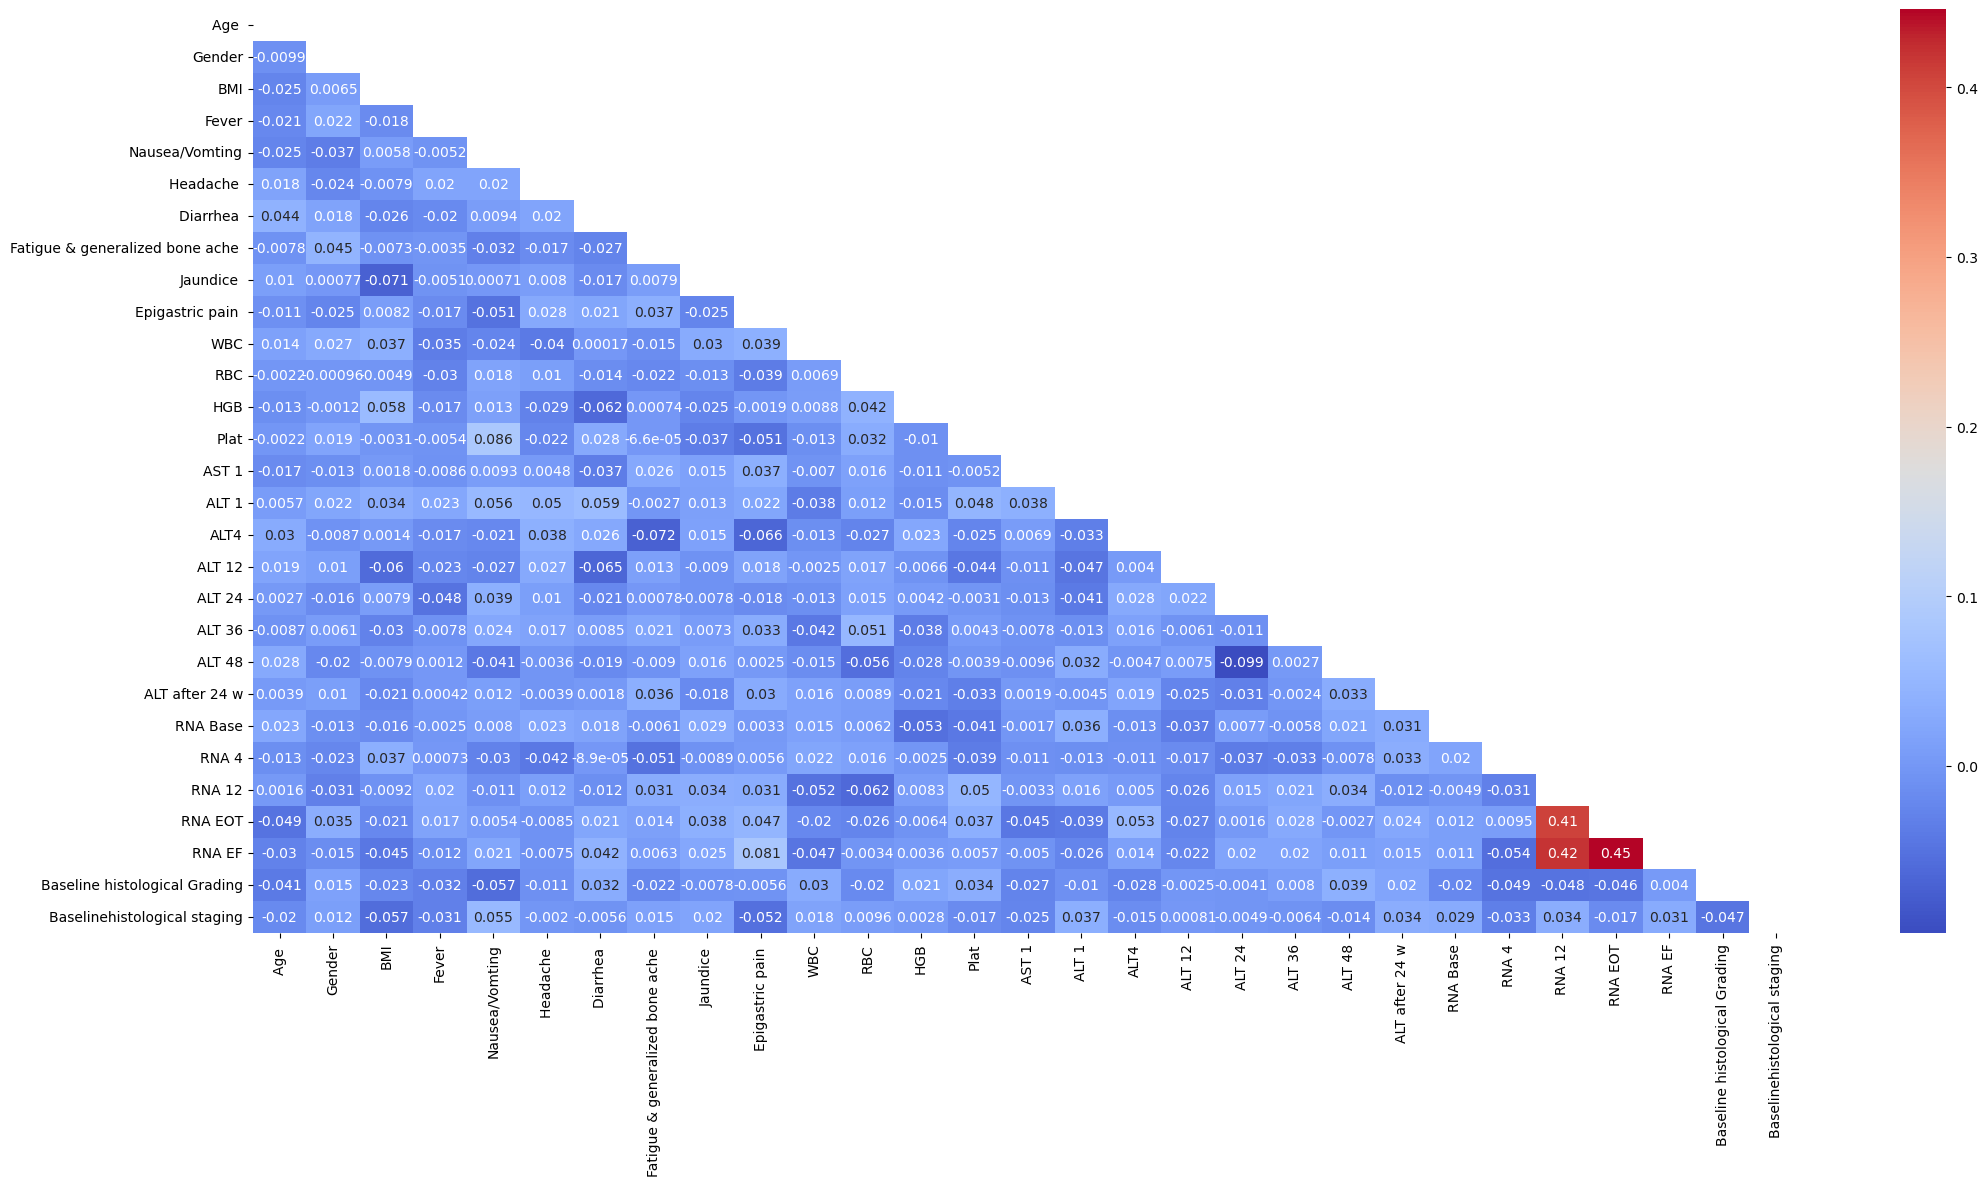

In [8]:
# visualising linear relationships in the dataset

correlations = df.corr()
plt.figure(figsize=(25, 12))
mask_1 = np.triu(correlations)
sns.heatmap(correlations, annot=True, mask = mask_1, cmap='coolwarm')


The plot here shows that variables have very weak relationships to each other, reflecting a degree of randomness in the data

# **Removing outliers for analysis**

In [9]:
# Calculate first quartile (25th percentile) for each numerical column
Q1 = df[numerical_columns].quantile(0.25)

# Calculate third quartile (75th percentile)
Q3 = df[numerical_columns].quantile(0.75)

# Compute Interquartile Range (IQR)
IQR = Q3 - Q1

# Identify outliers using IQR rule
outliers = (df[numerical_columns] < (Q1 - 1.5 * IQR)) \
            | (df[numerical_columns] > (Q3 + 1.5 * IQR))

# Remove rows where any column contains an outlier
df_clean = df[~outliers.any(axis=1)]

# View cleaned dataset
df_clean

,Age,Gender,BMI,Fever,Nausea/Vomting,Headache,Diarrhea,Fatigue & generalized bone ache,Jaundice,Epigastric pain,WBC,RBC,HGB,Plat,AST 1,ALT 1,ALT4,ALT 12,ALT 24,ALT 36,ALT 48,ALT after 24 w,RNA Base,RNA 4,RNA 12,RNA EOT,RNA EF,Baseline histological Grading,Baselinehistological staging
1,46,1,29,1,2,2,1,2,2,1,12101,4429425.0,10,129367.0,91,123,95.0,75,113,57,123,44,40620,538635,637056,336804,31085,4,2
3,49,2,33,1,2,1,2,1,2,1,6490,4794631.0,10,146457.0,43,64,109.0,80,88,48,77,33,1041941,449939,585688,744463,582301,10,3
5,58,2,22,2,2,2,1,2,2,1,11785,3882456.0,15,131228.0,66,104,121.0,96,65,73,114,29,1157452,1086852,5,5,5,4,4
6,42,2,26,1,1,2,2,2,2,2,11620,4747333.0,12,177261.0,78,57,113.0,118,107,84,80,28,325694,1034008,275095,214566,635157,12,4
7,48,2,30,1,1,2,2,1,1,2,7335,4405941.0,11,216176.0,119,112,80.0,127,45,96,53,39,641129,72050,787295,370605,506296,12,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1380,44,1,29,1,2,2,2,1,1,1,7044,4957174.0,15,202520.0,122,59,78.0,106,127,63,44,45,387795,55938,5,5,5,15,4
1381,55,1,34,1,2,2,1,1,1,1,6207,4636951.0,10,115776.0,128,102,65.0,99,108,97,64,41,481378,152961,393339,73574,236273,10,2
1382,42,1,26,2,2,1,1,1,2,1,4913,4122038.0,14,128354.0,61,93,123.0,61,116,87,39,24,612664,572756,806109,343719,160457,6,2
1383,52,1,29,2,1,1,2,2,2,1,7257,4241990.0,10,205908.0,70,97,104.0,74,47,48,81,43,139872,76161,515730,2460,696074,15,3


In [10]:
# Identify rows that contain at least one outlier across numerical columns
outlier_row_mask = outliers.any(axis=1)

# Keep only the outlier values (non-outliers become NaN)
outlier_values = df[numerical_columns].where(outliers)

# Filter to rows that actually contain outliers
outlier_values = outlier_values[outlier_row_mask]

# Outlier removal using isolation forrest

In [11]:
# Initialize Isolation Forest for anomaly detection

iso_outliers = IsolationForest(n_estimators=100, max_samples=256, contamination=0.05,
                               random_state = 42)

# Fit model on numerical features and predict anomalies

iso_pred = iso_outliers.fit_predict(df[numerical_columns])

# Create binary outlier flag column (True = outlier)
df['outlier'] = (iso_pred == -1)

In [12]:
# Creating a new dataset free from outliers

df_clean_iso = df[~df['outlier']]
df_clean_iso = df_clean_iso.drop(index=outlier_values.index, errors='ignore')
df_clean_iso.drop(columns = 'outlier')

,Age,Gender,BMI,Fever,Nausea/Vomting,Headache,Diarrhea,Fatigue & generalized bone ache,Jaundice,Epigastric pain,WBC,RBC,HGB,Plat,AST 1,ALT 1,ALT4,ALT 12,ALT 24,ALT 36,ALT 48,ALT after 24 w,RNA Base,RNA 4,RNA 12,RNA EOT,RNA EF,Baseline histological Grading,Baselinehistological staging
1,46,1,29,1,2,2,1,2,2,1,12101,4429425.0,10,129367.0,91,123,95.0,75,113,57,123,44,40620,538635,637056,336804,31085,4,2
3,49,2,33,1,2,1,2,1,2,1,6490,4794631.0,10,146457.0,43,64,109.0,80,88,48,77,33,1041941,449939,585688,744463,582301,10,3
5,58,2,22,2,2,2,1,2,2,1,11785,3882456.0,15,131228.0,66,104,121.0,96,65,73,114,29,1157452,1086852,5,5,5,4,4
6,42,2,26,1,1,2,2,2,2,2,11620,4747333.0,12,177261.0,78,57,113.0,118,107,84,80,28,325694,1034008,275095,214566,635157,12,4
7,48,2,30,1,1,2,2,1,1,2,7335,4405941.0,11,216176.0,119,112,80.0,127,45,96,53,39,641129,72050,787295,370605,506296,12,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1380,44,1,29,1,2,2,2,1,1,1,7044,4957174.0,15,202520.0,122,59,78.0,106,127,63,44,45,387795,55938,5,5,5,15,4
1381,55,1,34,1,2,2,1,1,1,1,6207,4636951.0,10,115776.0,128,102,65.0,99,108,97,64,41,481378,152961,393339,73574,236273,10,2
1382,42,1,26,2,2,1,1,1,2,1,4913,4122038.0,14,128354.0,61,93,123.0,61,116,87,39,24,612664,572756,806109,343719,160457,6,2
1383,52,1,29,2,1,1,2,2,2,1,7257,4241990.0,10,205908.0,70,97,104.0,74,47,48,81,43,139872,76161,515730,2460,696074,15,3


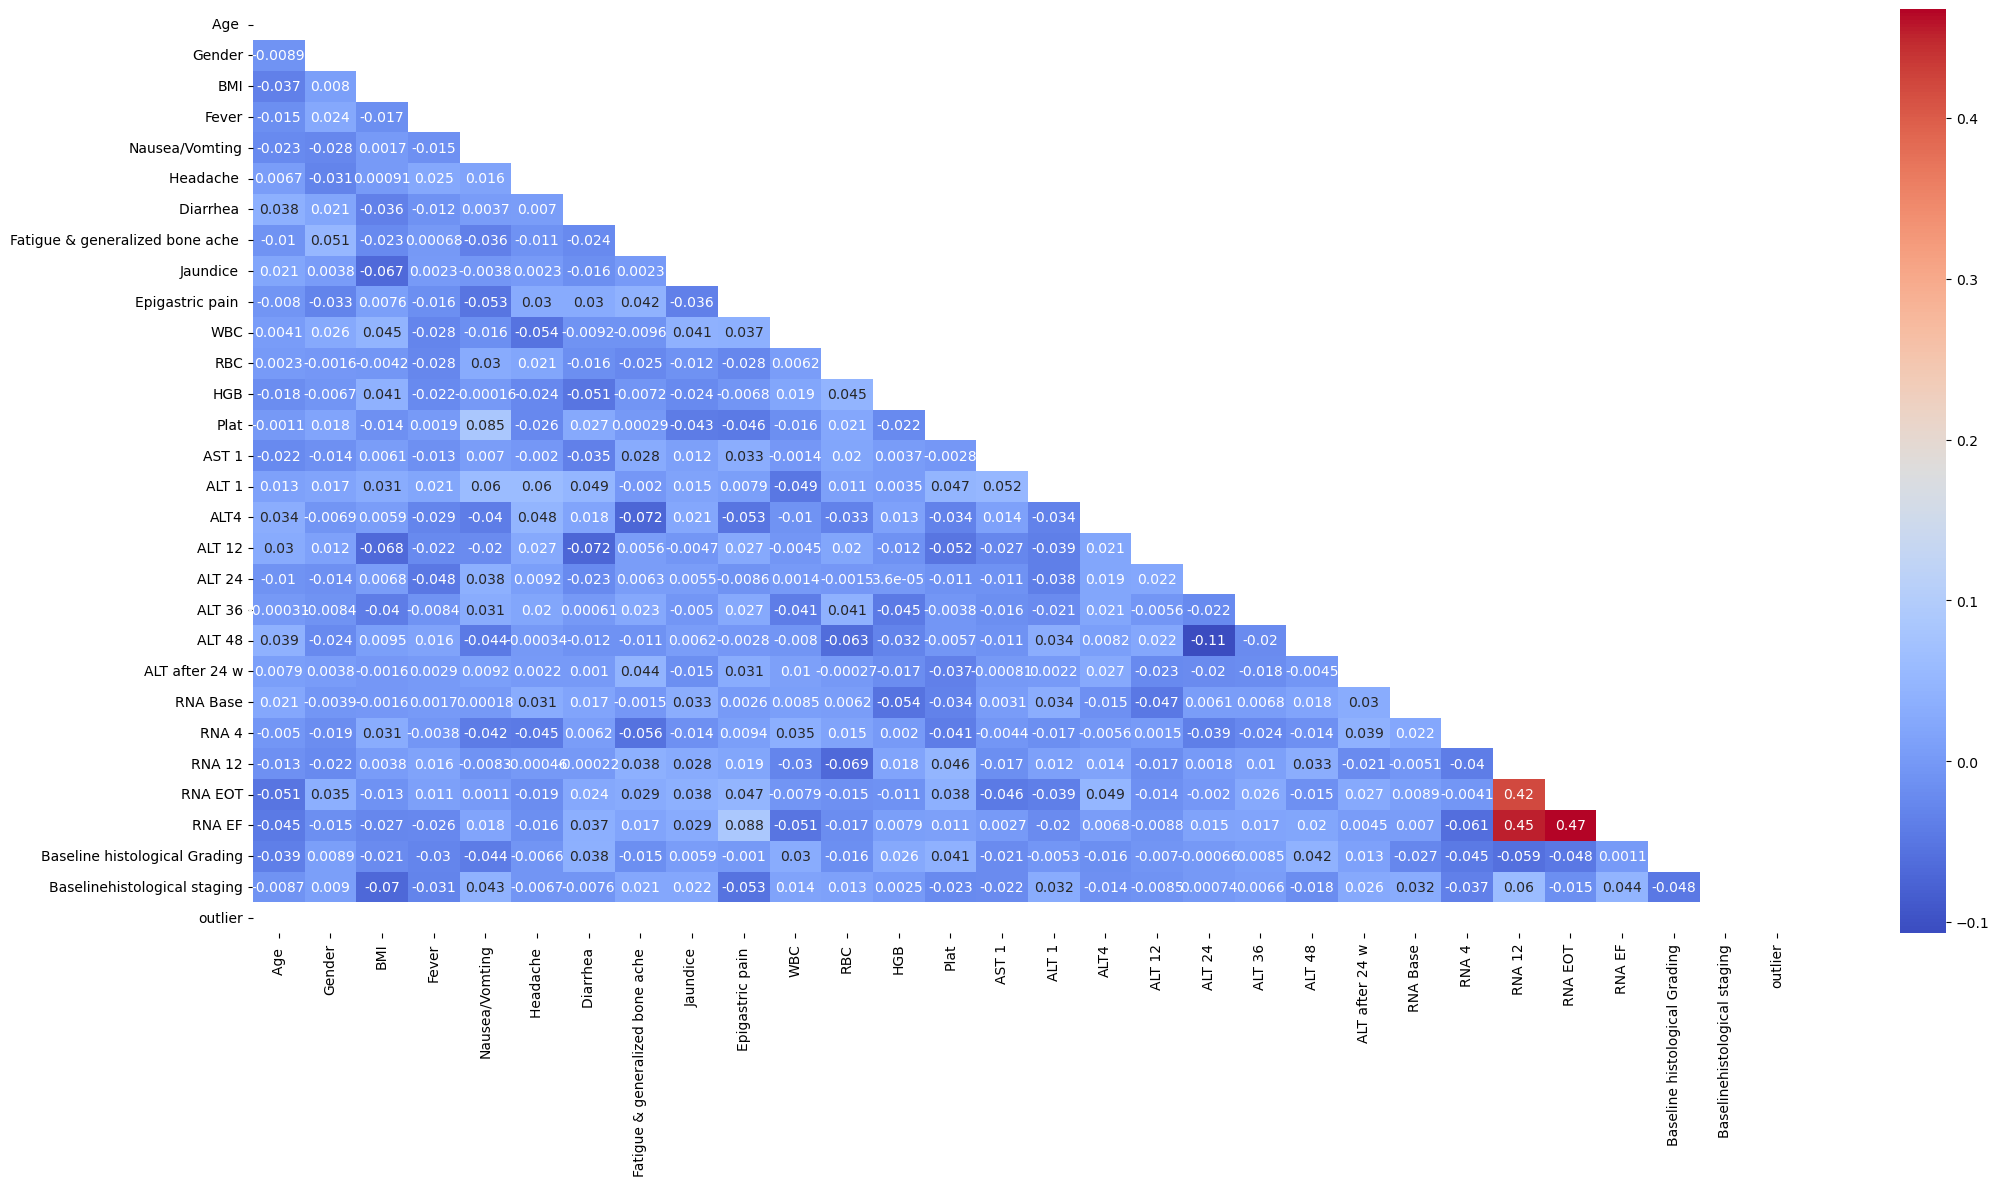

In [13]:
# testing correlations after outlier removal

clean_corr = df_clean_iso.corr()

mask = np.triu(np.ones_like(clean_corr))

plt.figure(figsize=(25, 12))

sns.heatmap(clean_corr, annot=True, cmap='coolwarm', mask=mask)

plt.show()

Outlier removal has reflected no effect on the relationships between variables in the dataset

# **Normality and data distribution analysis**

In [14]:
# normality tests for numerical columns

normality_results = []

for col in numerical_columns:
    data = df_clean_iso[col].dropna()

    if len(data) < 3:
        continue

    stat_sw, p_sw = shapiro(data)

    try:
        stat_dp, p_dp = normaltest(data)
    except:
        stat_dp, p_dp = np.nan, np.nan

    normality_results.append({
        "Column": col,
        "Mean": data.mean(),
        "Median": data.median(),
        "Std": data.std(),
        "Skewness": skew(data),
        "Kurtosis": kurtosis(data),
        "Shapiro_p": p_sw,
        "Shapiro_Normal": p_sw > 0.05,
        "D_Agostino_p": p_dp,
        "D_Agostino_Normal": p_dp > 0.05 if not np.isnan(p_dp) else np.nan
    })

normality_df = pd.DataFrame(normality_results)
normality_df

,Column,Mean,Median,Std,Skewness,Kurtosis,Shapiro_p,Shapiro_Normal,D_Agostino_p,D_Agostino_Normal
0,Age,4.623839e+01,46.0,8.682948,0.016340,-1.229157,9.895101e-21,False,2.903154e-283,False
1,BMI,2.865575e+01,29.0,4.038345,-0.036300,-1.236787,2.446031e-22,False,4.348288e-305,False
2,WBC,7.567987e+03,7521.0,2647.257377,0.008157,-1.212215,4.916676e-20,False,7.395437e-243,False
3,RBC,4.423288e+06,4439101.0,345185.197789,-0.050617,-1.181655,2.664121e-19,False,1.696048e-189,False
4,HGB,1.259482e+01,13.0,1.688927,-0.043616,-1.240046,2.418601e-27,False,0.000000e+00,False
5,Plat,1.583852e+05,157979.0,38609.725119,0.032106,-1.186825,1.267912e-19,False,3.903830e-197,False
6,AST 1,8.293602e+01,83.0,25.797503,0.022886,-1.183691,2.268937e-19,False,2.210685e-192,False
7,ALT 1,8.405941e+01,83.0,25.681524,0.019971,-1.154899,7.679095e-19,False,8.362174e-156,False
8,ALT4,8.355903e+01,83.0,26.196689,0.017442,-1.235895,1.317226e-20,False,2.331699e-302,False
9,ALT 12,8.362376e+01,84.0,25.738485,-0.016818,-1.168127,3.732291e-19,False,3.312088e-171,False


Results show that none of the numerical variables in the dataset follow a normal-bell curve distribution

# Q-Q plot

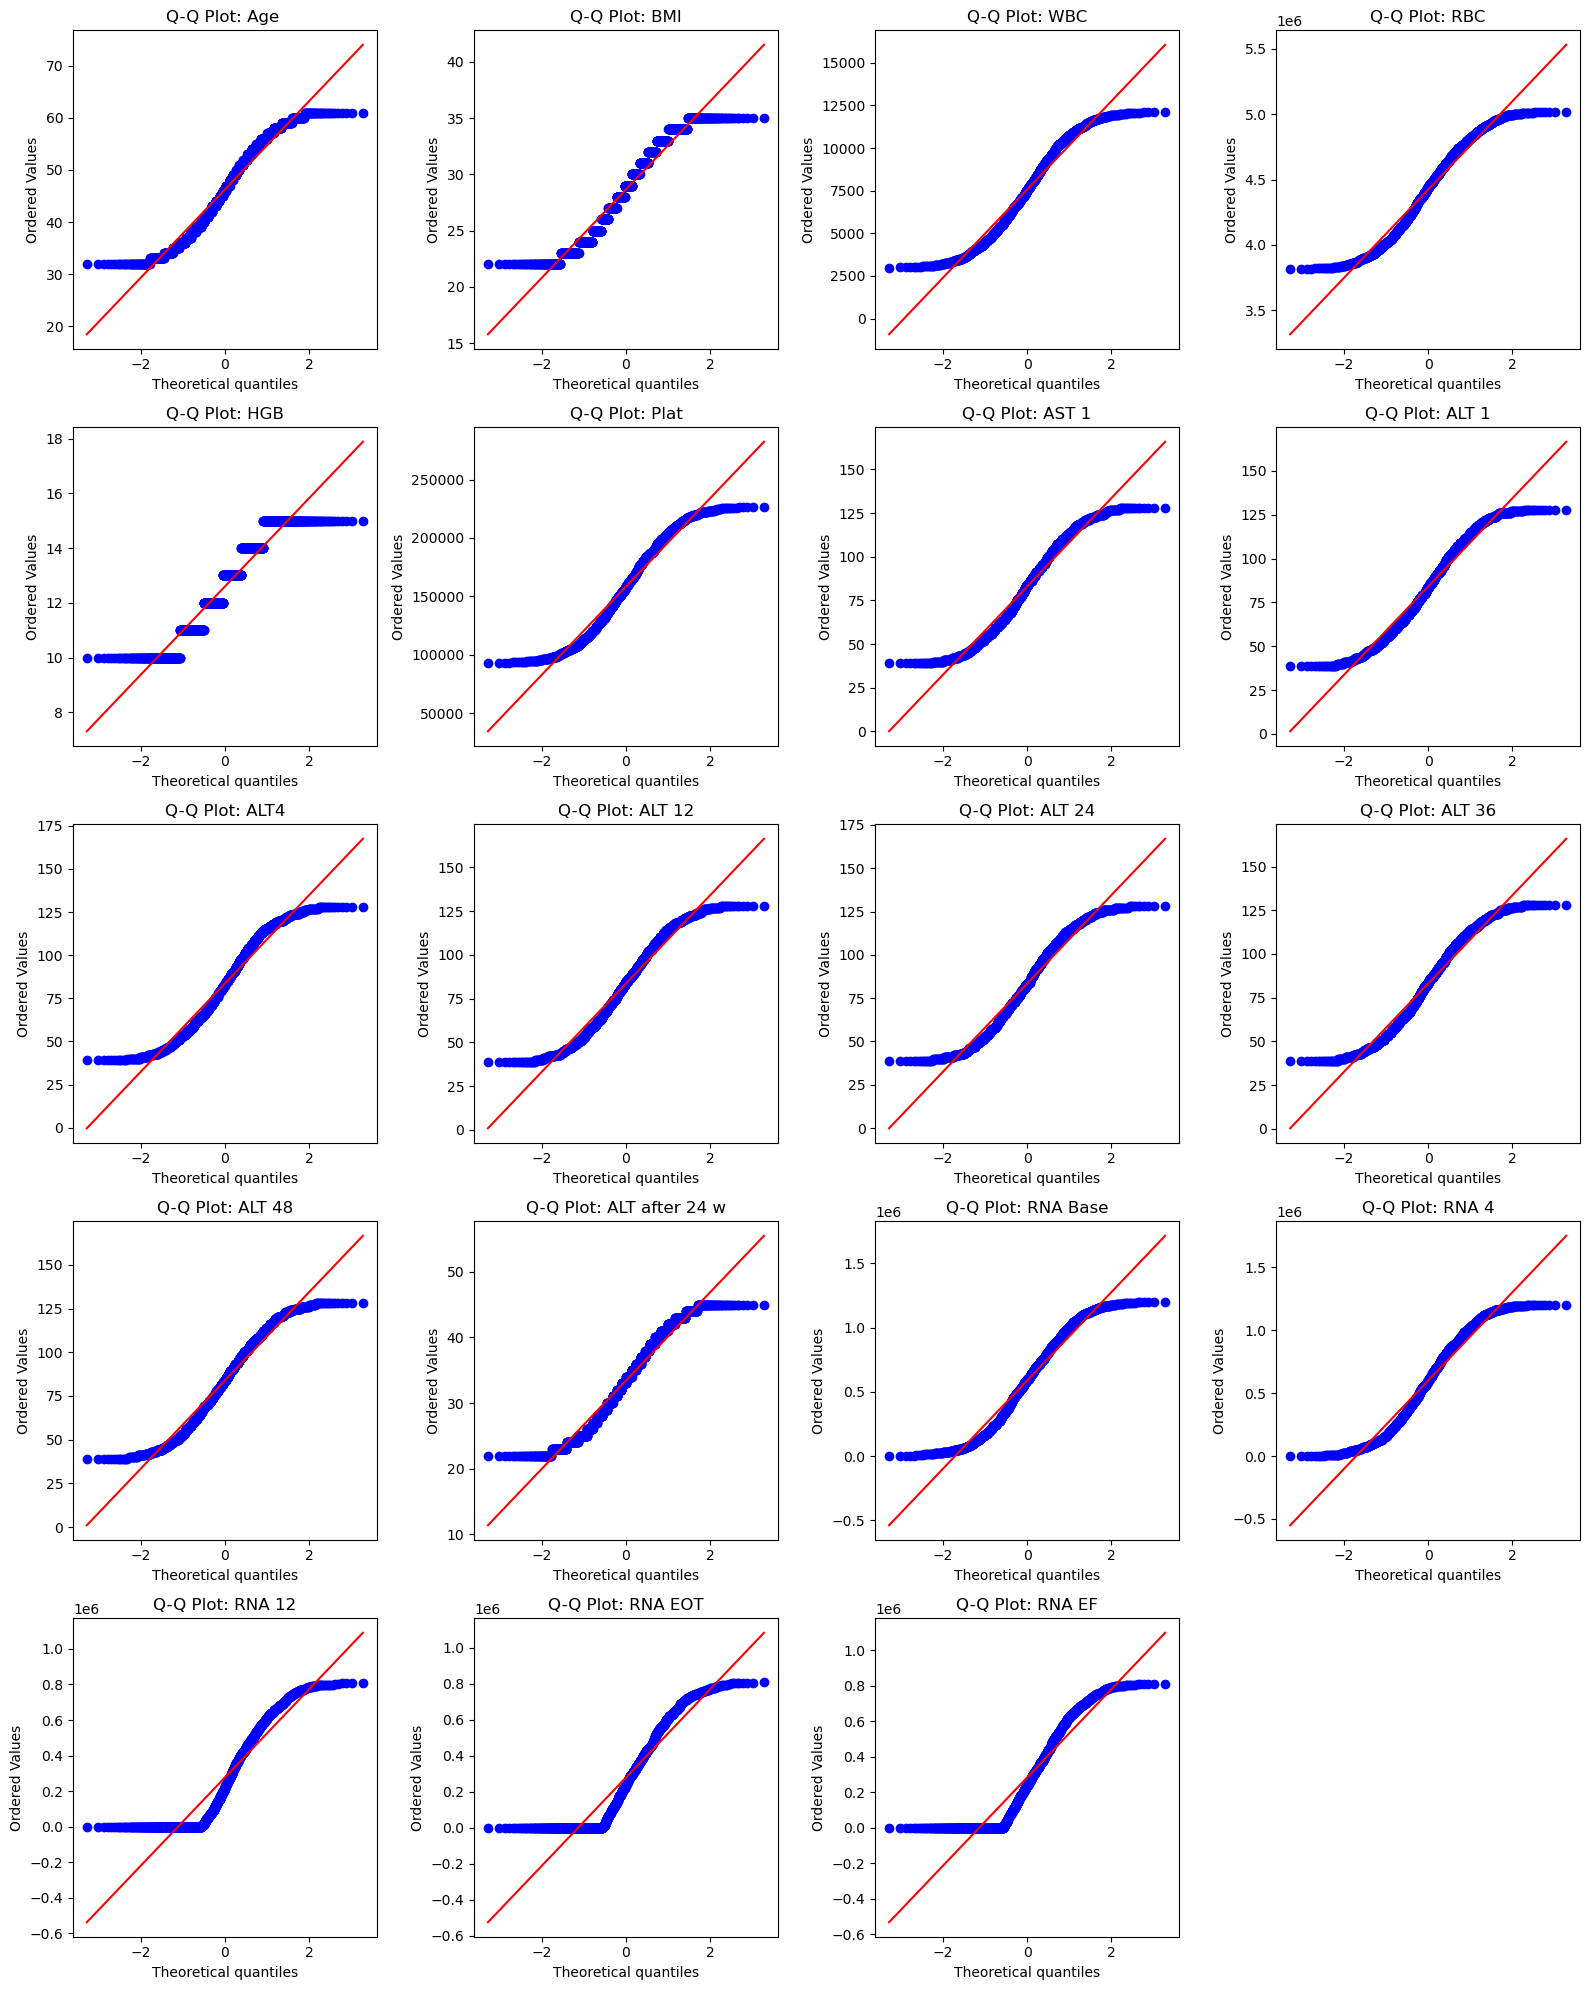

In [15]:
# Q-Q plots for numerical columns

n_cols = 4
n_rows = math.ceil(len(numerical_columns) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numerical_columns):
    data = df_clean_iso[col].dropna()

    stats.probplot(data, dist="norm", plot=axes[i])
    axes[i].set_title(f"Q-Q Plot: {col}")

# remove empty plots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

QQ-plot confirms abnormal distribution of variables

# Histograms to visualise data distribution

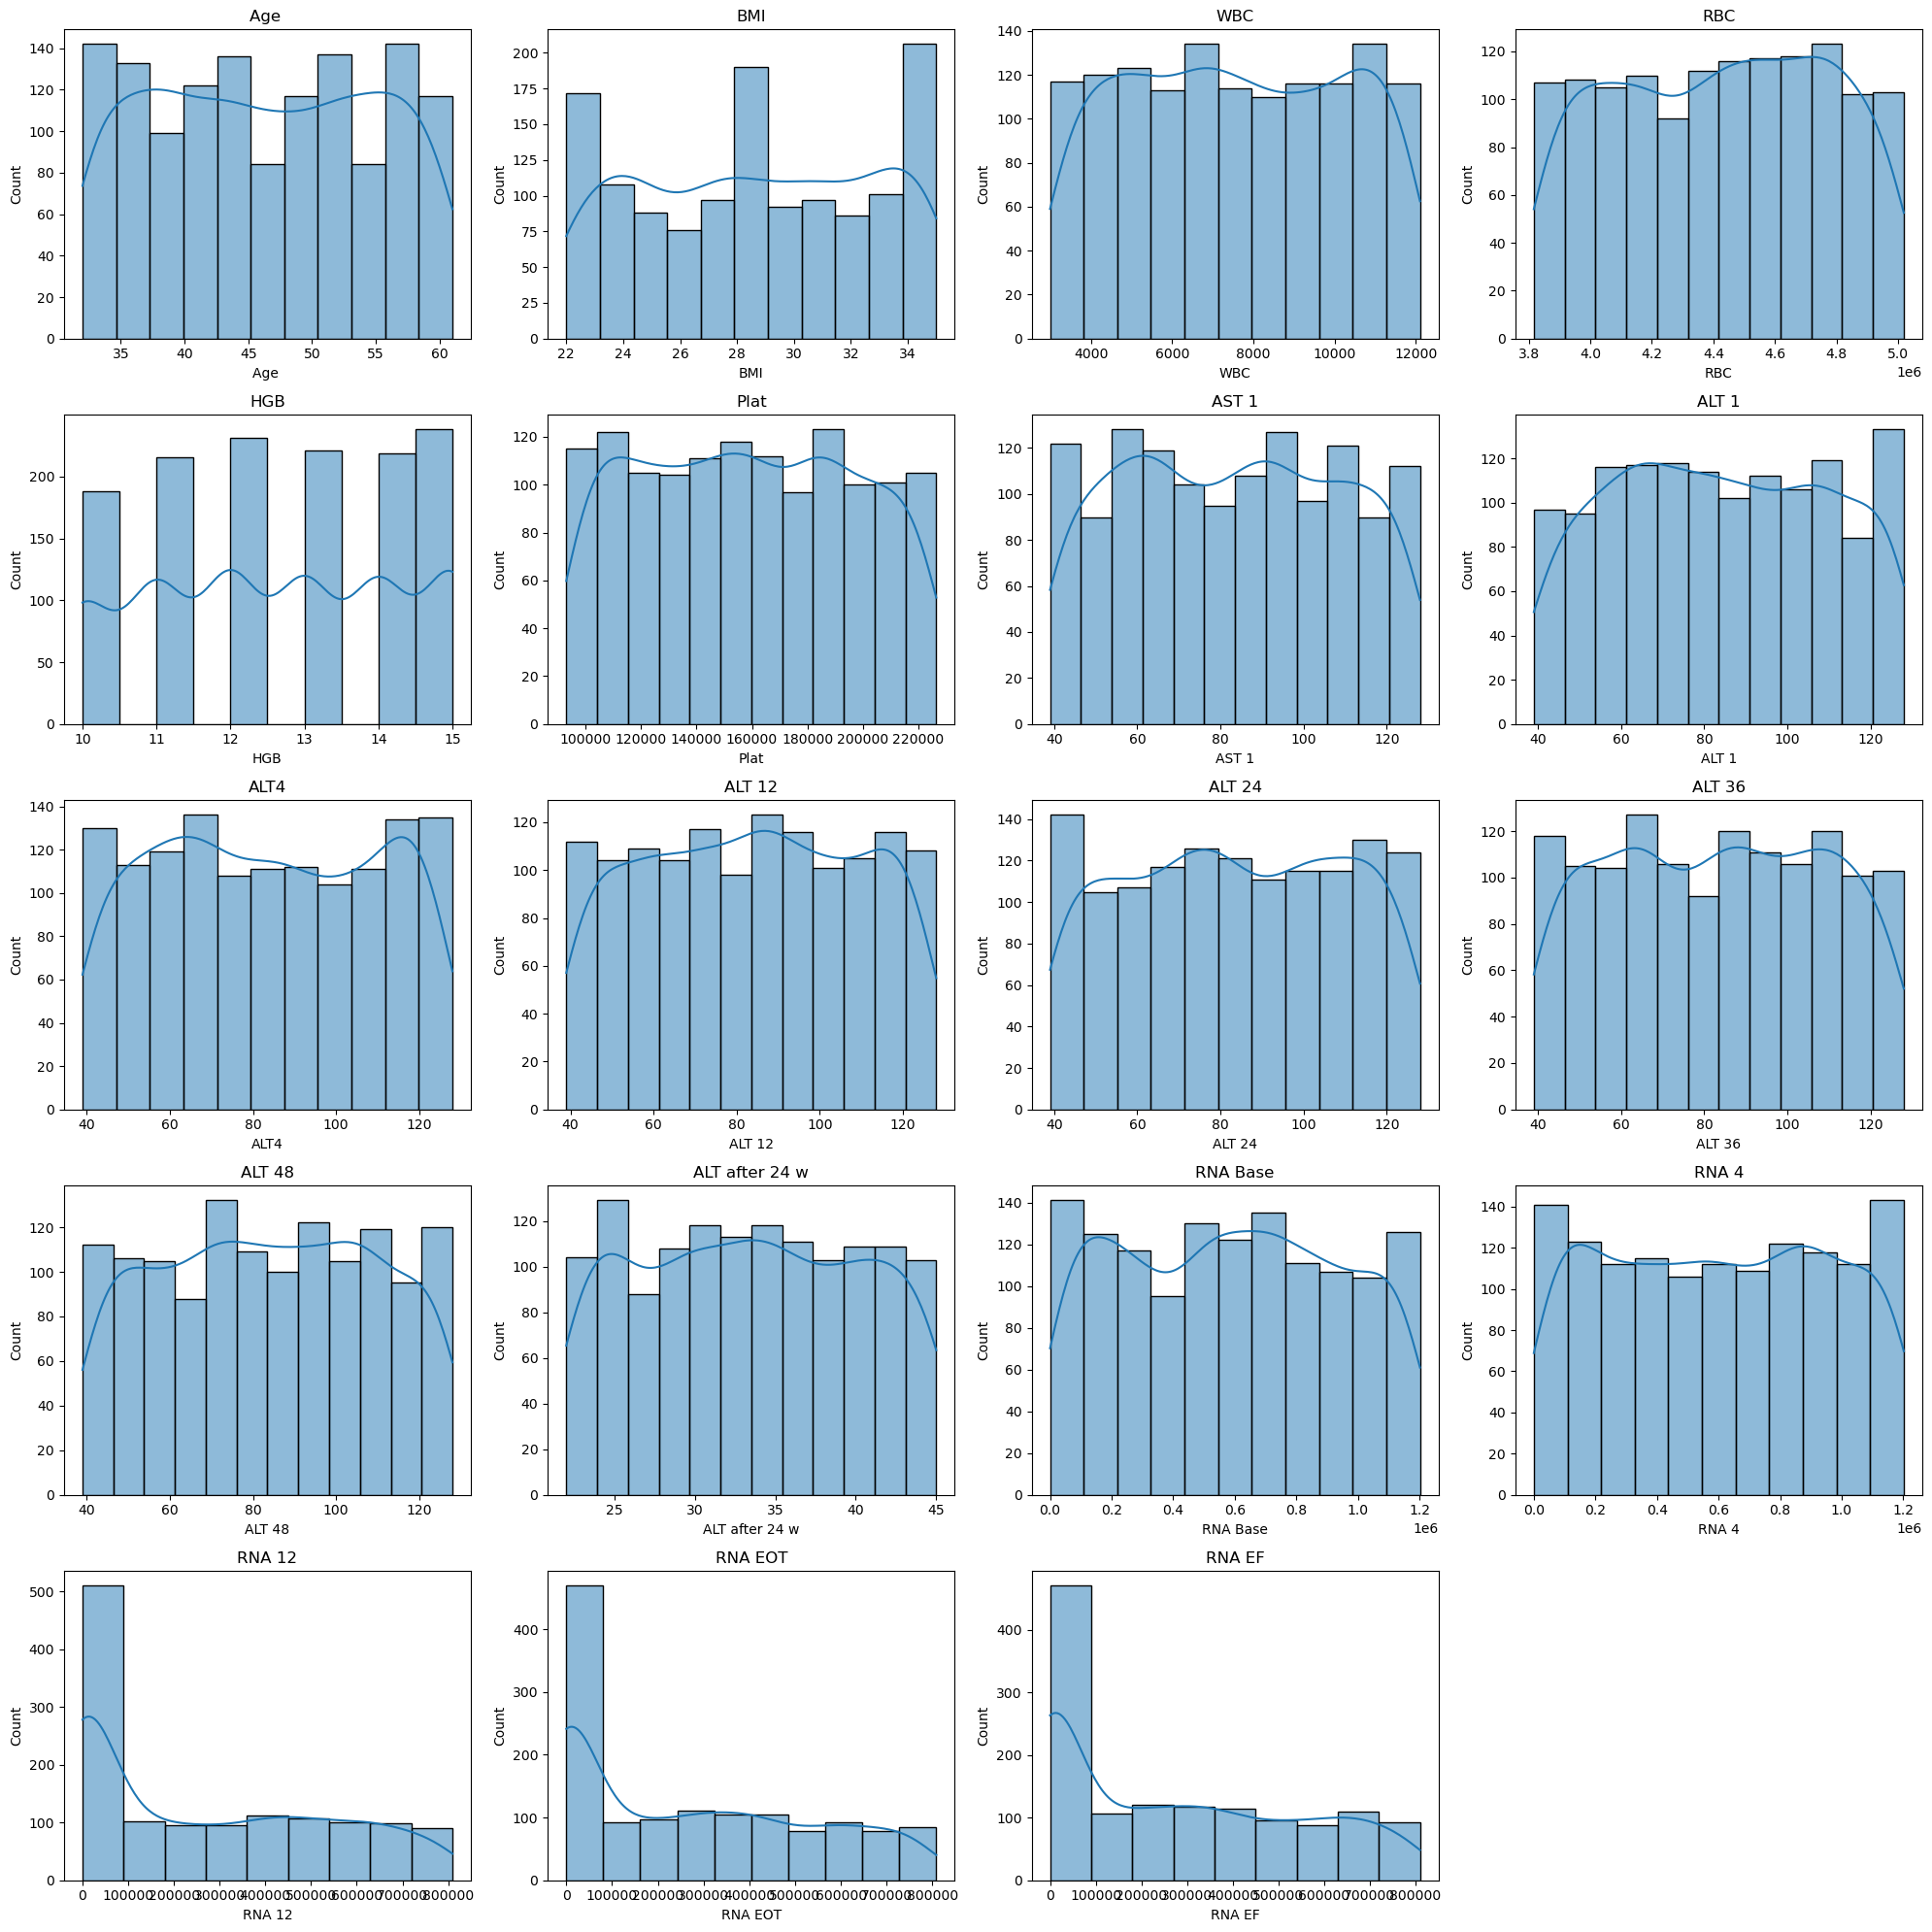

In [16]:
# distribution plots (4 per row)

n = len(numerical_columns)
fig, axes = plt.subplots((n + 3)//4, 4, figsize=(20, 4*((n + 3)//4)))
axes = axes.flatten()

for i, col in enumerate(numerical_columns):
    sns.histplot(df_clean_iso[col].dropna(), bins='fd', kde=True, ax=axes[i])
    axes[i].set_title(col)

# remove empty subplot if odd number
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

The distribution analysis shows that the majority of numerical variables do not follow a clear normal distribution. Demographic and routine laboratory variables such as age, BMI, WBC, RBC, platelets, AST and ALT values are widely distributed, while HGB appears discretised, suggesting grouped or rounded measurements. The RNA follow-up variables, particularly RNA 12, RNA EOT and RNA EF, show strong right skewness, with many observations concentrated at very low values and fewer patients showing high viral-load values. This indicates that the dataset contains non-normal and skewed clinical measurements, meaning that non-parametric tests and robust machine learning models are more appropriate than methods that assume normally distributed variables.

# **Statistical testing**

In [17]:
# defining an empty list
alt_columns = []

# collecting ALT columns for statistical testing
for column in df_clean_iso.columns:
  if 'ALT' in column:
    alt_columns.append(column)

# defining an empty list
rna_columns = []

# collecting RNA columns for statistical testing
for column in df_clean_iso.columns:
  if 'RNA' in column:
    rna_columns.append(column)

print(alt_columns)
print('')
print(rna_columns)

['ALT 1', 'ALT4', 'ALT 12', 'ALT 24', 'ALT 36', 'ALT 48', 'ALT after 24 w']

['RNA Base', 'RNA 4', 'RNA 12', 'RNA EOT', 'RNA EF']


# Kruskal wallis test for significance

In [18]:
# merging test columns
test_columns = alt_columns + rna_columns

# defining empty lidst to gather results
kruskal_results = []

# loop for kruskal wallis test of significance
for col in test_columns:

  test_data = df_clean_iso[[col, 'Baselinehistological staging']]
  stages = test_data['Baselinehistological staging'].unique()
  test_groups = [test_data[test_data['Baselinehistological staging'] == stage][col]
        for stage in sorted(test_data['Baselinehistological staging'].unique())]

  h_stat, p_val = stats.kruskal(*test_groups)

  # calculate effect size
  n = len(test_data)
  k = test_data['Baselinehistological staging'].nunique()
  eta_squared = (h_stat - k + 1) / (n - k)

  kruskal_results.append({
        'Variable': col,
        'H_statistic': h_stat,
        'p_value': p_val,
        'eta_squared': eta_squared})

kruskal_df = pd.DataFrame(kruskal_results)
kruskal_df = kruskal_df.sort_values(by='eta_squared', ascending=False)

print(kruskal_df)

          Variable  H_statistic   p_value  eta_squared
11          RNA EF     7.107261  0.068556     0.003138
9           RNA 12     3.723775  0.292878     0.000553
8            RNA 4     2.413276  0.491168    -0.000448
0            ALT 1     2.393397  0.494865    -0.000463
7         RNA Base     2.378922  0.497570    -0.000474
6   ALT after 24 w     2.111995  0.549490    -0.000678
5           ALT 48     1.373671  0.711718    -0.001242
1             ALT4     0.893654  0.826959    -0.001609
4           ALT 36     0.851438  0.837128    -0.001641
2           ALT 12     0.345293  0.951297    -0.002028
10         RNA EOT     0.196276  0.978188    -0.002142
3           ALT 24     0.017423  0.999392    -0.002279


The Kruskal-Wallis results show that none of the ALT or RNA variables differ significantly across fibrosis stages, as all p-values are above 0.05 and the eta-squared values are close to zero, indicating extremely weak explanatory power.



In [19]:
# transforming data into a normal distribution
qt = QuantileTransformer(output_distribution='normal', random_state=42)

df_transformed = df_clean_iso.copy()
df_transformed[numerical_columns] = qt.fit_transform(df_clean_iso[numerical_columns])

# empty list for results
anova_results = []

test_columns = alt_columns + rna_columns

for col in test_columns:

    data = df_transformed[[col, 'Baselinehistological staging']].dropna()

    groups = [
        data[data['Baselinehistological staging'] == stage][col]
        for stage in sorted(data['Baselinehistological staging'].unique())
    ]

    f_stat, p_value = f_oneway(*groups)

    anova_results.append({
        'Variable': col,
        'F_statistic': f_stat,
        'p_value': p_value
    })

anova_df = pd.DataFrame(anova_results).sort_values(by='p_value')
print(anova_df)

          Variable  F_statistic   p_value
4           ALT 36     1.352688  0.255762
8            RNA 4     1.147190  0.328844
11          RNA EF     0.949508  0.415900
5           ALT 48     0.893073  0.444064
2           ALT 12     0.740202  0.528103
9           RNA 12     0.673789  0.568146
1             ALT4     0.510135  0.675342
7         RNA Base     0.456260  0.712914
0            ALT 1     0.326233  0.806404
6   ALT after 24 w     0.238774  0.869340
10         RNA EOT     0.224016  0.879738
3           ALT 24     0.108572  0.955106


Conclusion:
After applying QuantileTransformer to make the variables closer to a normal distribution, one-way ANOVA still found no significant differences between fibrosis stages for any ALT or RNA variable. This suggests that the weak relationship between these variables and fibrosis stage is not simply caused by non-normality.

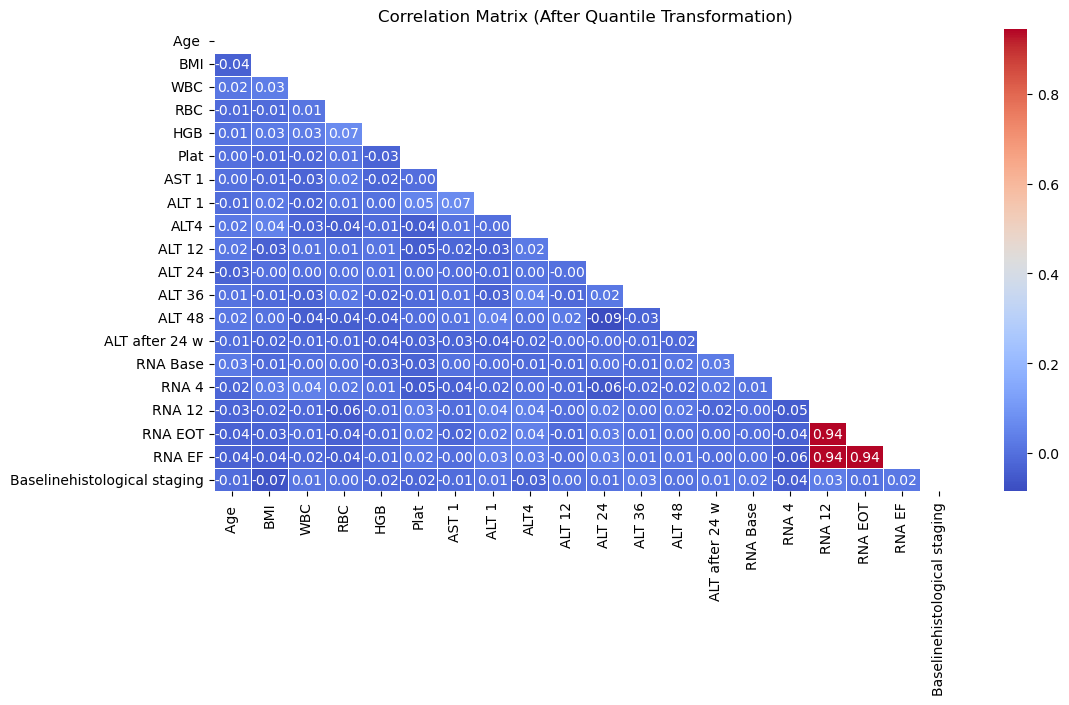

In [20]:
# correlation for transformed data
corr_cols = numerical_columns + ['Baselinehistological staging']
corr_matrix = df_transformed[corr_cols].corr(method='pearson')

# create mask for upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12,6))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Matrix (After Quantile Transformation)")
plt.show()

After quantile transformation, the correlation matrix still shows almost no meaningful relationship between the clinical variables and baseline histological staging, although RNA 12, RNA EOT and RNA EF increased in correlation with each other.

# **Machine learning exploration**

In [21]:
# testing predictive power of different timepoints

early = ['ALT 1', 'ALT4', 'RNA Base', 'RNA 4']
mid   = ['ALT 12', 'RNA 12', 'ALT 24']
late  = ['ALT 36', 'ALT 48', 'RNA EOT']

In [22]:
def evaluate_model(features):
    X = df_clean_iso[features]
    y = df_clean_iso['Baselinehistological staging']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

    model = RandomForestClassifier(random_state=42)
    model.fit(X_train, y_train)

    preds = model.predict(X_test)
    return accuracy_score(y_test, preds)

In [23]:
print("Early:", evaluate_model(early))
print("Mid:", evaluate_model(mid))
print("All:", evaluate_model(early + mid + late))

Early: 0.2639593908629442
Mid: 0.3350253807106599
All: 0.2182741116751269


middle time cut-offs have strongest predictive power.

# **Machine learning training and modelling**

# Data preparation

In [24]:
df_clean_iso = df_clean_iso.drop(columns=['ALT 36', 'ALT 48', 'ALT after 24 w', 'RNA EOT', 'Baseline histological Grading','outlier']
                                 , errors='ignore')

In [25]:
# defining training and target features

X = df_clean_iso.drop(columns=['Baselinehistological staging'], axis=1)
y = df_clean_iso['Baselinehistological staging']

# Train - test split\

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Logistic regression

In [26]:
# defining logistic regression pipeline
log_pipeline = Pipeline([
    ('transformer', QuantileTransformer(output_distribution = 'normal', random_state=42)),
    ('classifier', LogisticRegression(penalty="l2",
        C=1.0,
        solver="lbfgs",
        max_iter=1000,
        class_weight="balanced",
        random_state=42 ))])

# training pipeline
log_pipeline.fit(X_train, y_train)

# testing pipeline
log_preds = log_pipeline.predict(X_test)

# evaluating predictions
log_results = classification_report(y_test, log_preds)
print(log_results)

              precision    recall  f1-score   support

           1       0.23      0.19      0.21        62
           2       0.21      0.25      0.23        64
           3       0.25      0.25      0.25        68
           4       0.17      0.16      0.16        69

    accuracy                           0.21       263
   macro avg       0.21      0.21      0.21       263
weighted avg       0.21      0.21      0.21       263



The model performs poorly, with only 21% accuracy and low F1-scores across all fibrosis stages, indicating it is barely better than random guessing for a four-class classification problem.

# Calibration plot - Logistic Regression

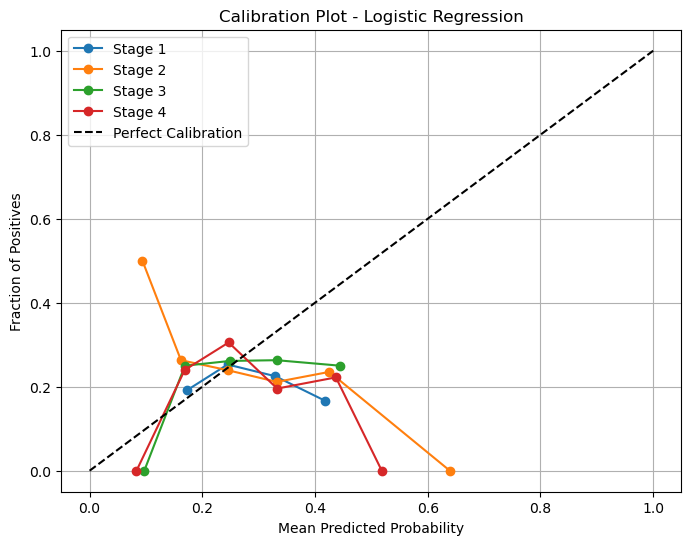

In [27]:
# getting predicted probabilities from logistic regression
log_probs = log_pipeline.predict_proba(X_test)

# getting the class labels
classes = log_pipeline.classes_

# binarising y_test for one-vs-rest calibration plotting
y_test_bin = label_binarize(y_test, classes=classes)

# plotting calibration curve
plt.figure(figsize=(8, 6))

# loop through each fibrosis stage
for i, class_label in enumerate(classes):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin[:, i],
        log_probs[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=f'Stage {class_label}')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Logistic Regression')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature distribution - logistic regression

Data preparation

In [28]:
# creating a copy of the test data
log_error_df = X_test.copy()

# adding actual and predicted fibrosis stages
log_error_df['Actual_Stage'] = y_test.values
log_error_df['Predicted_Stage'] = log_preds

# checking if the prediction was correct or incorrect
log_error_df['Prediction_Result'] = np.where(
    log_error_df['Actual_Stage'] == log_error_df['Predicted_Stage'],
    'Correct',
    'Incorrect'
)

# checking the dataframe
log_error_df.head()

,Age,Gender,BMI,Fever,Nausea/Vomting,Headache,Diarrhea,Fatigue & generalized bone ache,Jaundice,Epigastric pain,WBC,RBC,HGB,Plat,AST 1,ALT 1,ALT4,ALT 12,ALT 24,RNA Base,RNA 4,RNA 12,RNA EF,Actual_Stage,Predicted_Stage,Prediction_Result
1061,47,2,22,2,1,2,1,2,1,2,5047,4736716.0,12,100970.0,64,71,86.0,94,79,1181946,689599,676614,385059,4,1,Incorrect
10,37,2,24,2,1,2,1,2,2,1,4437,4265042.0,12,166027.0,103,124,111.0,74,53,1023123,103190,731929,59998,2,4,Incorrect
158,45,1,22,2,1,2,2,2,2,1,4249,4527245.0,14,130738.0,120,41,75.0,90,46,860017,368190,335255,753568,3,3,Correct
1135,49,2,25,2,2,1,2,2,2,1,8240,4116220.0,11,138179.0,40,65,122.0,79,41,15076,712169,419985,574911,1,2,Incorrect
1196,44,1,31,1,1,1,1,2,2,2,11028,5004447.0,14,222475.0,123,63,70.0,77,56,1101693,45456,358248,733035,4,2,Incorrect


Error plots - logistic regression

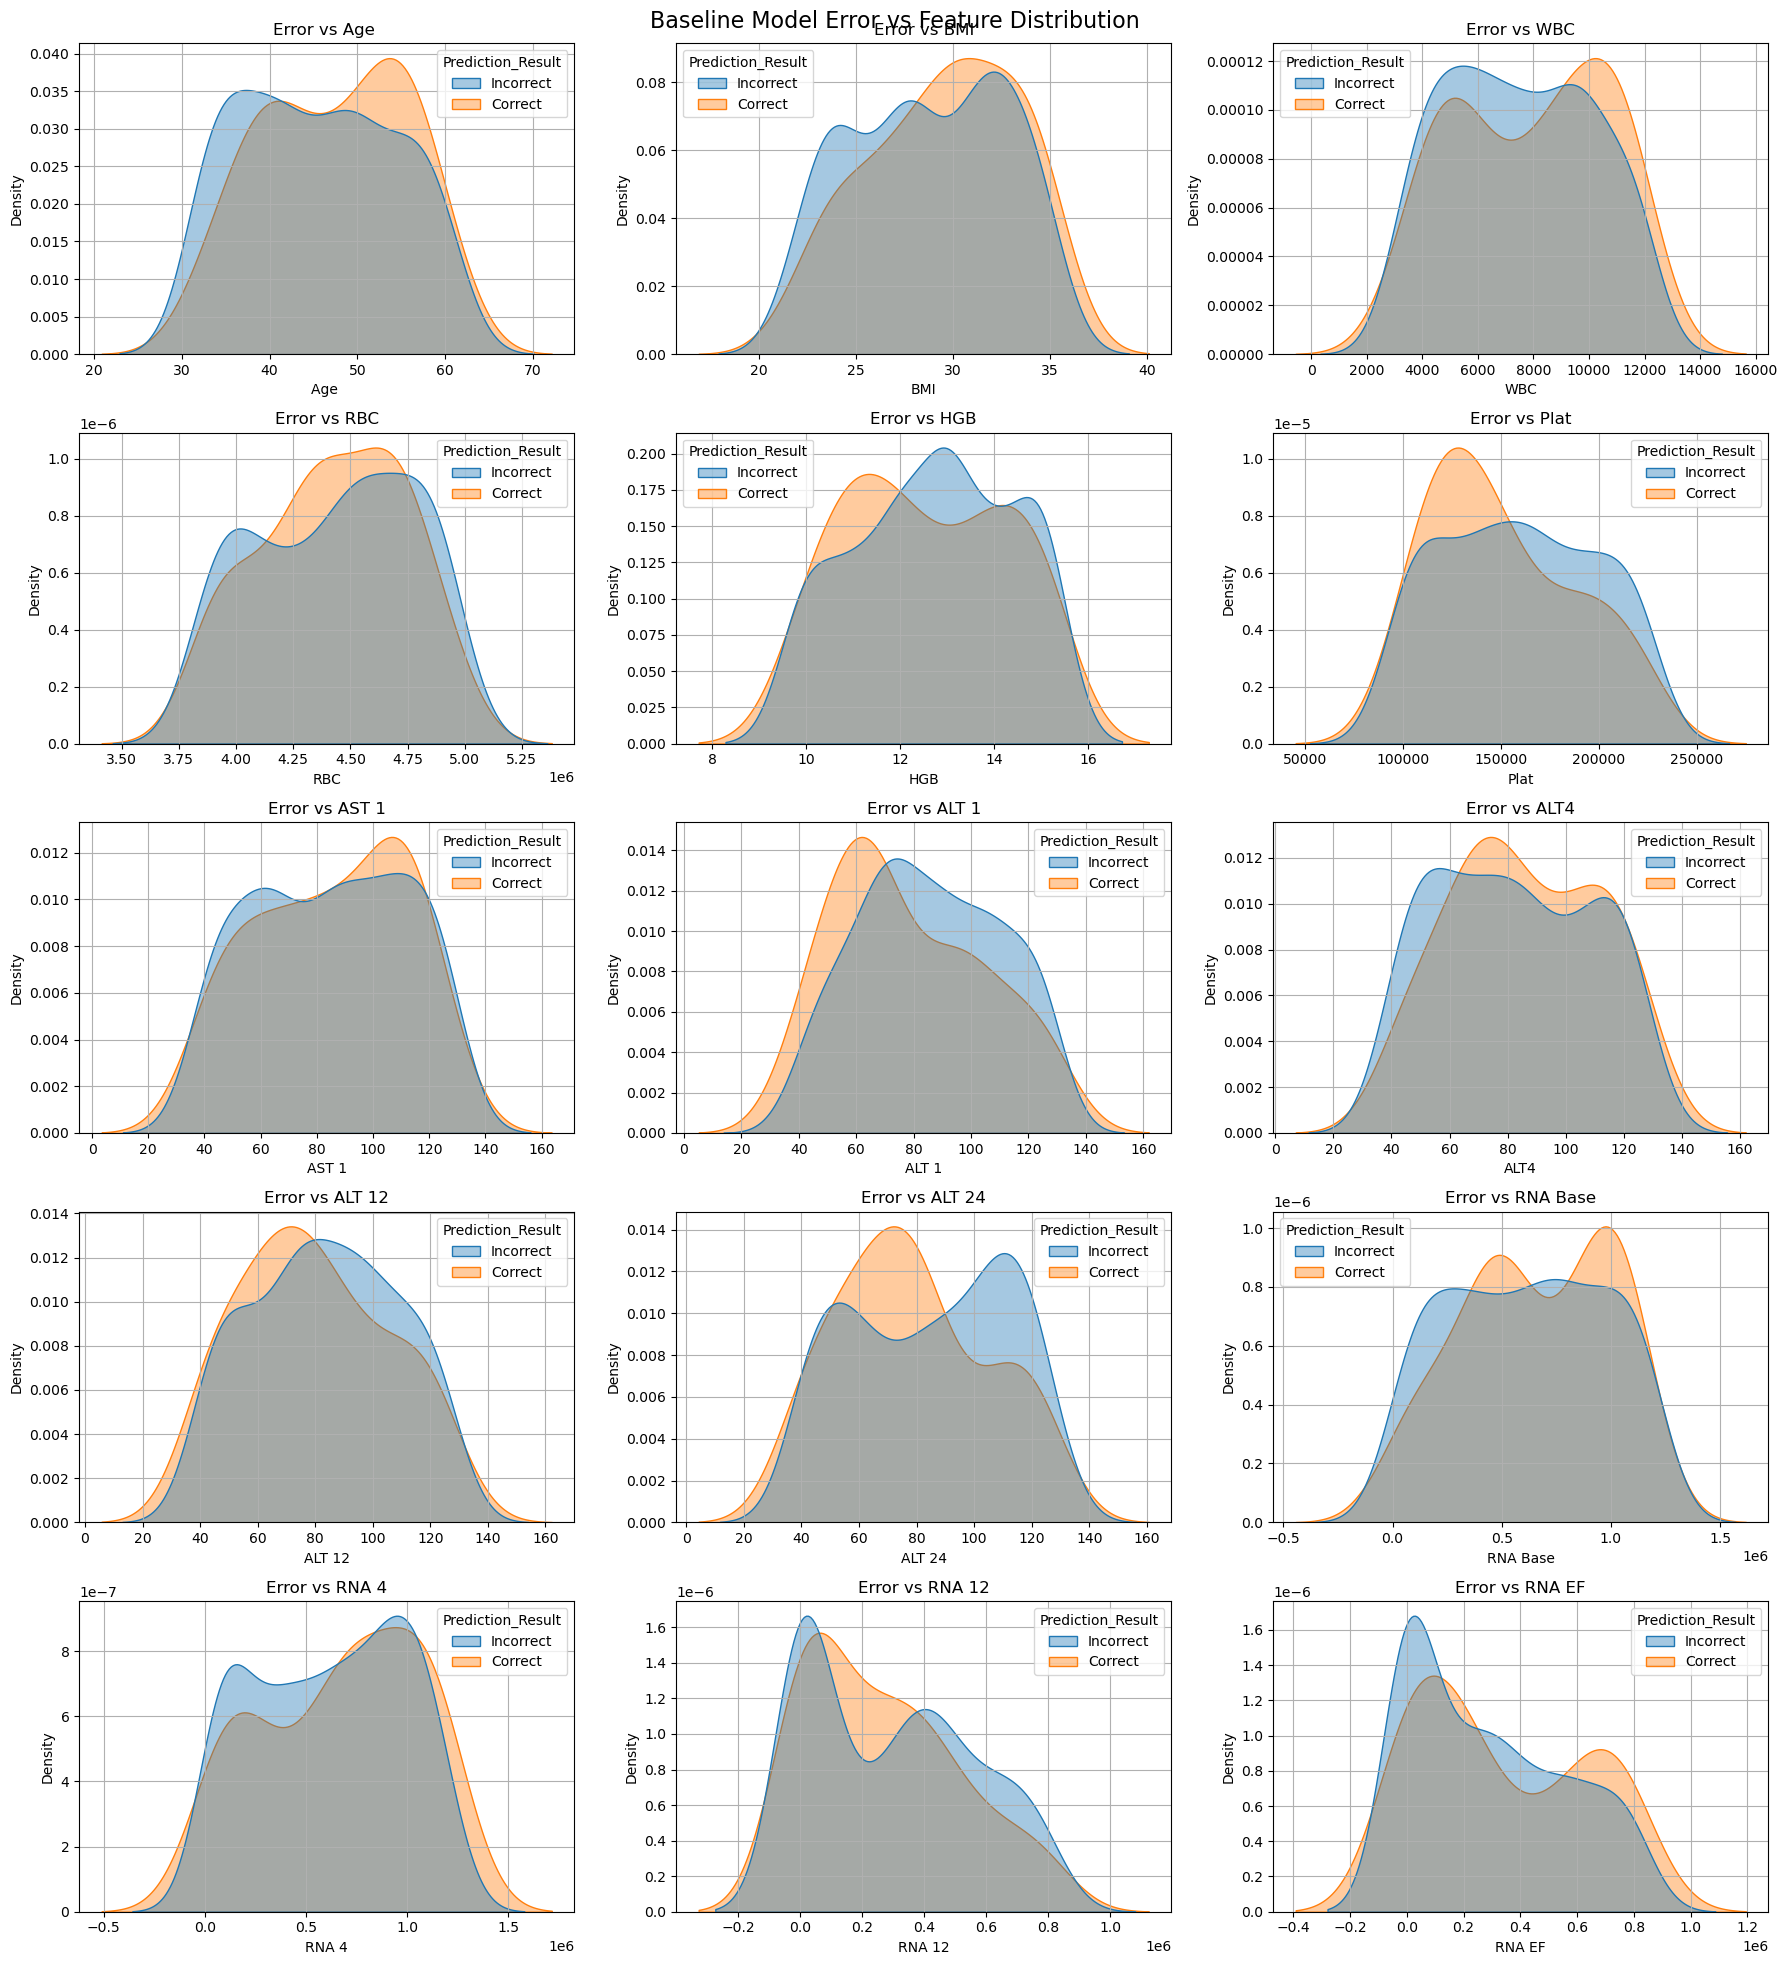

In [29]:
# choosing selected features to inspect
features_to_plot = [col for col in X_train.columns if col in numerical_columns]

# setting number of plots per row
plots_per_row = 3

# calculating number of rows needed
n_rows = math.ceil(len(features_to_plot) / plots_per_row)

# creating subplots
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=log_error_df,
        x=feature,
        hue='Prediction_Result',
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Baseline Model Error vs Feature Distribution', fontsize=16)
plt.tight_layout()
plt.show()

# Random forest

In [30]:
# defining random forest model
rf_model = RandomForestClassifier(
    n_estimators=200,        # number of trees
    max_depth=None,          # let trees grow fully
    min_samples_split=2,     # minimum samples to split
    min_samples_leaf=1,      # minimum samples per leaf
    max_features='sqrt',     # features considered per split
    class_weight='balanced',
    random_state=42,
    n_jobs=-1)

# training model
rf_model.fit(X_train, y_train)

# predictions
rf_preds = rf_model.predict(X_test)

# evaluating predictions
rf_results = classification_report(y_test, rf_preds)
print(rf_results)

              precision    recall  f1-score   support

           1       0.19      0.15      0.17        62
           2       0.18      0.14      0.16        64
           3       0.28      0.37      0.32        68
           4       0.25      0.28      0.26        69

    accuracy                           0.24       263
   macro avg       0.22      0.23      0.23       263
weighted avg       0.23      0.24      0.23       263



This model also performs poorly, with 24% accuracy and macro F1 of 0.23, showing weak class separation and no reliable ability to predict fibrosis stage.

Calibration plot - Random Forest

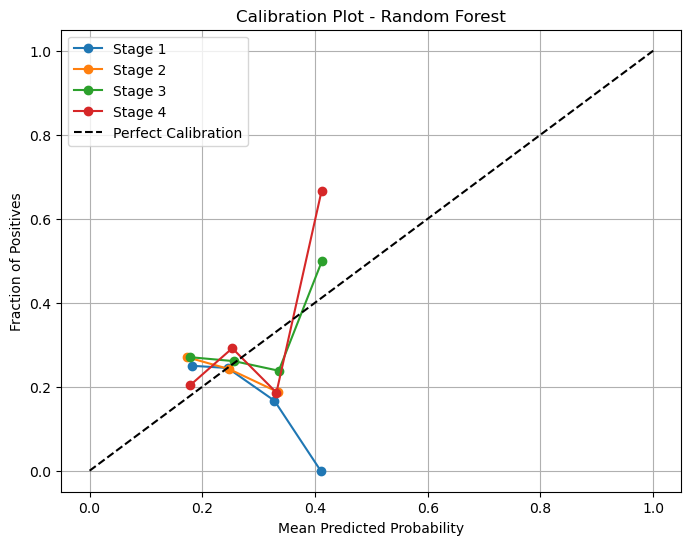

In [31]:
# getting predicted probabilities from random forest
rf_probs = rf_model.predict_proba(X_test)

# getting the class labels
classes = rf_model.classes_

# binarising y_test for one-vs-rest calibration plotting
y_test_bin = label_binarize(y_test, classes=classes)

# plotting calibration curve
plt.figure(figsize=(8, 6))

# loop through each fibrosis stage
for i, class_label in enumerate(classes):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin[:, i],
        rf_probs[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=f'Stage {class_label}')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Random Forest')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature plot - random forest

Data preparation

In [32]:
# creating a copy of the test data
rf_error_df = X_test.copy()

# adding actual and predicted fibrosis stages
rf_error_df['Actual_Stage'] = y_test.values
rf_error_df['Predicted_Stage'] = rf_preds

# checking if the prediction was correct or incorrect
rf_error_df['Prediction_Result'] = np.where(
    rf_error_df['Actual_Stage'] == rf_error_df['Predicted_Stage'],
    'Correct',
    'Incorrect'
)

# checking the dataframe
rf_error_df.head()

,Age,Gender,BMI,Fever,Nausea/Vomting,Headache,Diarrhea,Fatigue & generalized bone ache,Jaundice,Epigastric pain,WBC,RBC,HGB,Plat,AST 1,ALT 1,ALT4,ALT 12,ALT 24,RNA Base,RNA 4,RNA 12,RNA EF,Actual_Stage,Predicted_Stage,Prediction_Result
1061,47,2,22,2,1,2,1,2,1,2,5047,4736716.0,12,100970.0,64,71,86.0,94,79,1181946,689599,676614,385059,4,4,Correct
10,37,2,24,2,1,2,1,2,2,1,4437,4265042.0,12,166027.0,103,124,111.0,74,53,1023123,103190,731929,59998,2,1,Incorrect
158,45,1,22,2,1,2,2,2,2,1,4249,4527245.0,14,130738.0,120,41,75.0,90,46,860017,368190,335255,753568,3,3,Correct
1135,49,2,25,2,2,1,2,2,2,1,8240,4116220.0,11,138179.0,40,65,122.0,79,41,15076,712169,419985,574911,1,3,Incorrect
1196,44,1,31,1,1,1,1,2,2,2,11028,5004447.0,14,222475.0,123,63,70.0,77,56,1101693,45456,358248,733035,4,4,Correct


Error plots - random forest

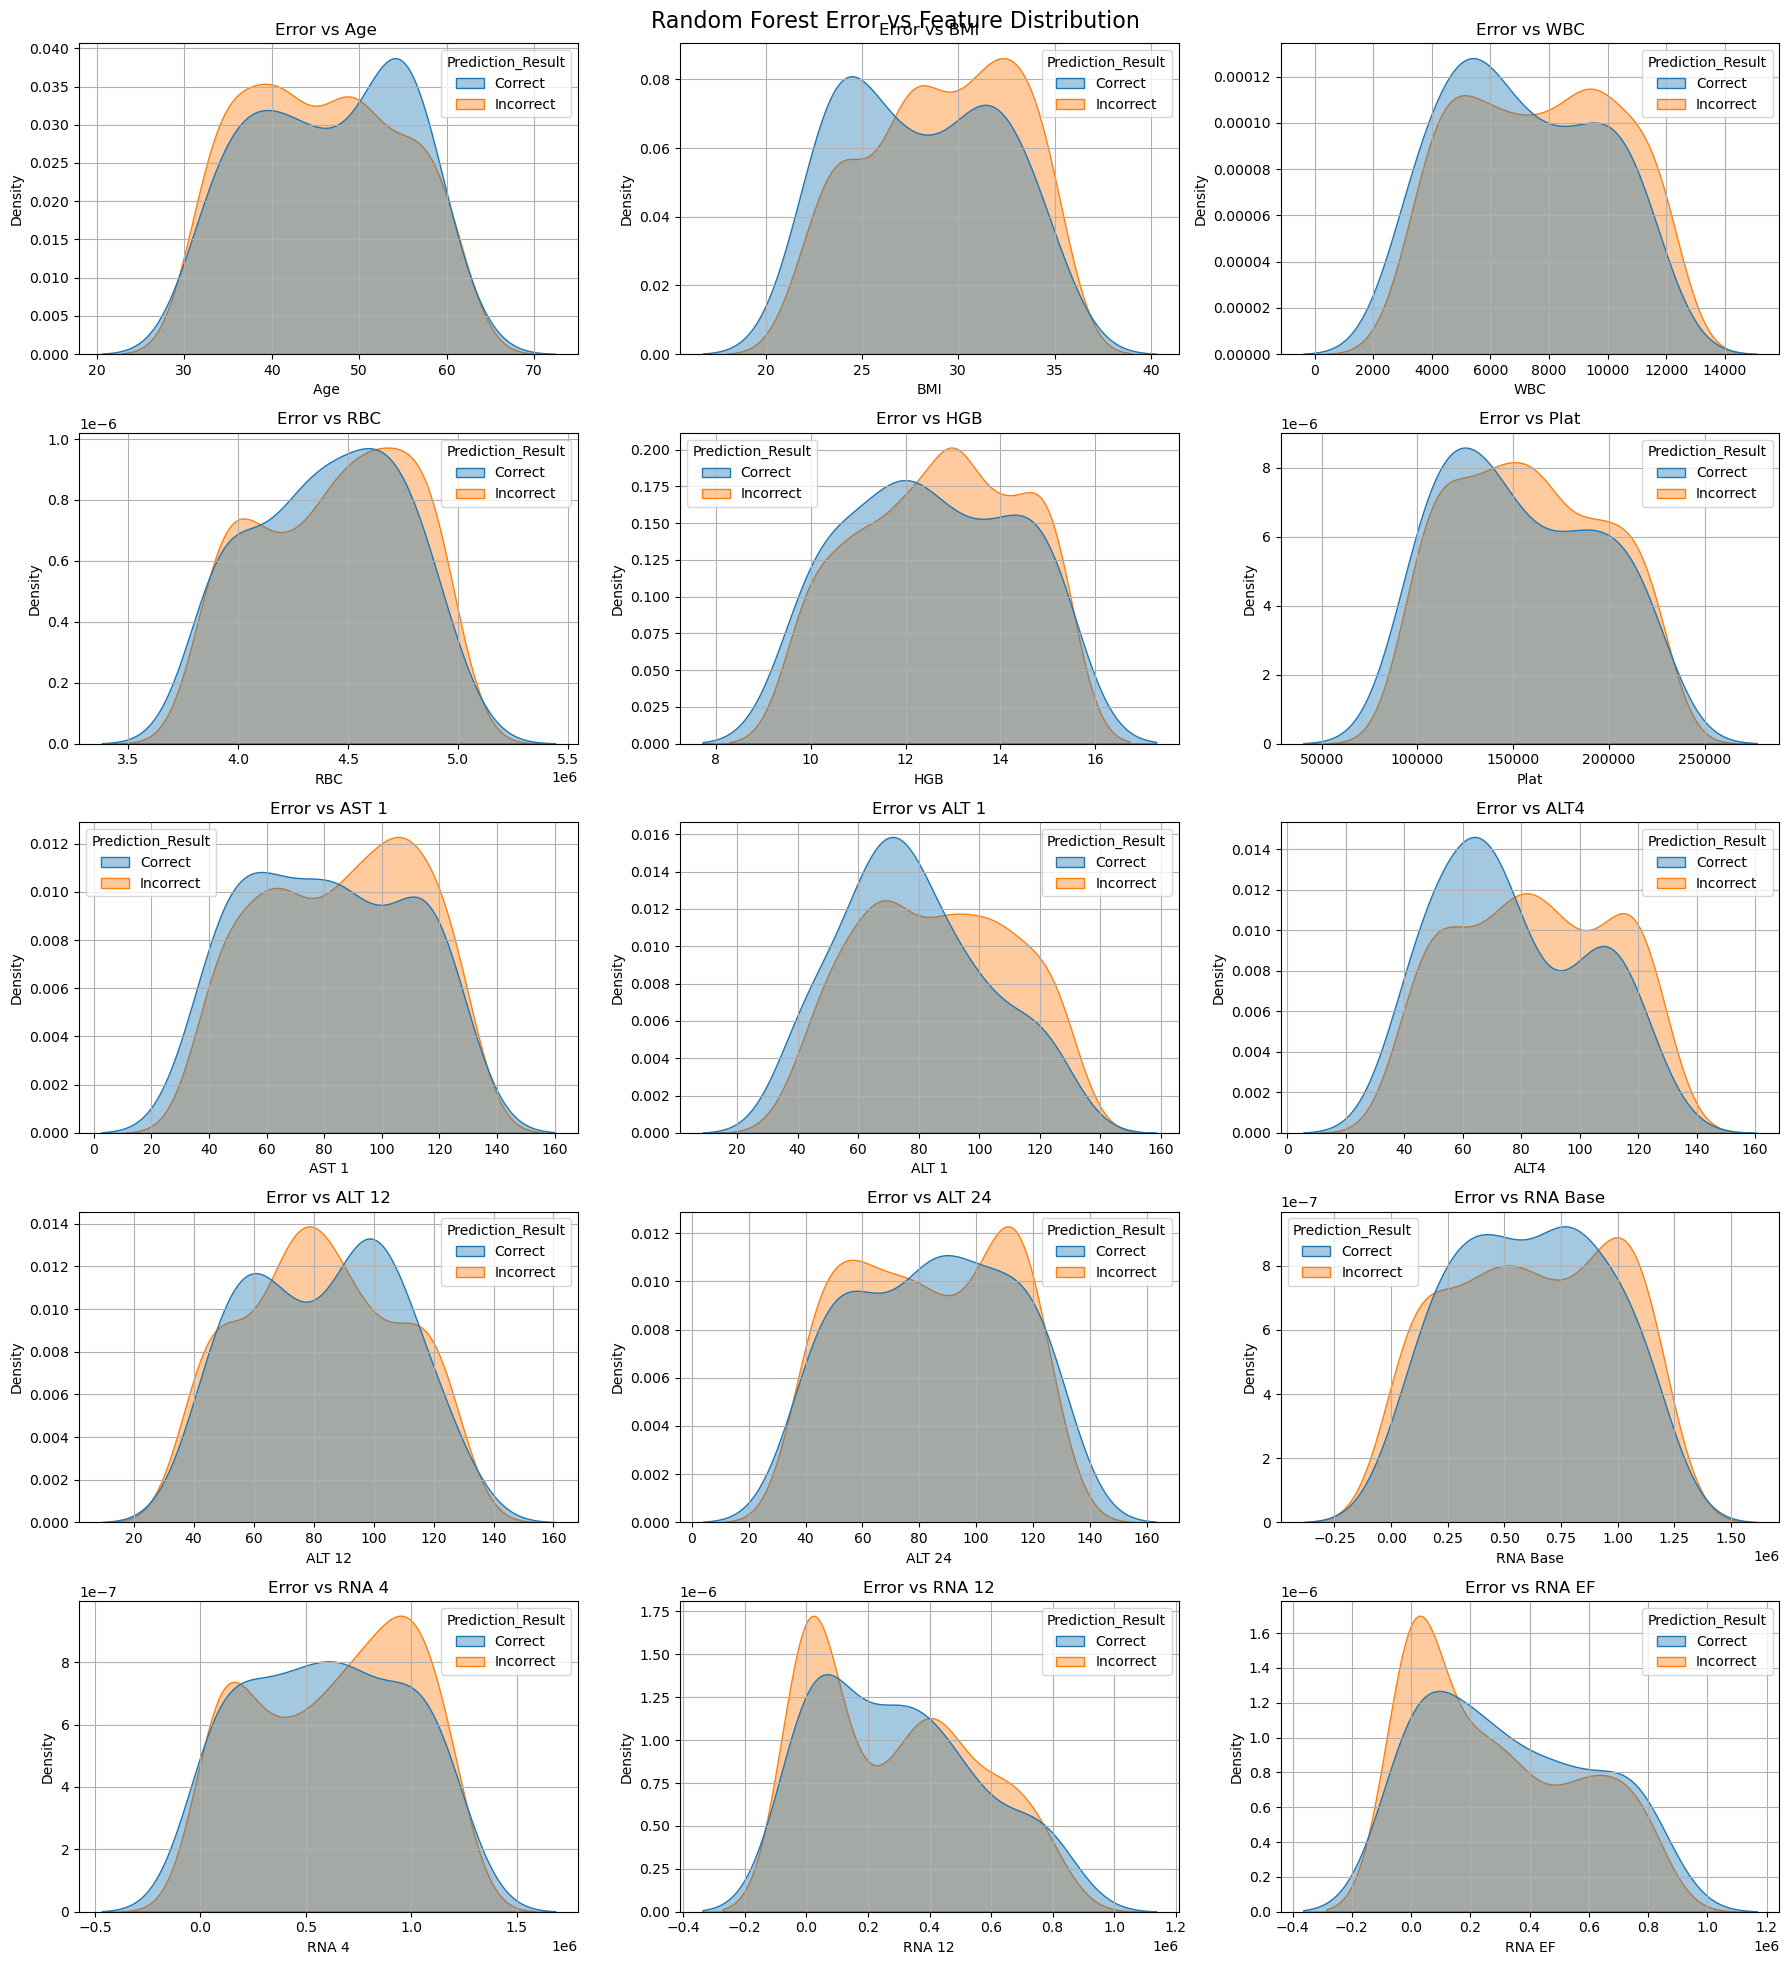

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
import math

# choosing selected features to inspect
features_to_plot = [col for col in X_train.columns if col in numerical_columns]

# setting number of plots per row
plots_per_row = 3

# calculating number of rows needed
n_rows = math.ceil(len(features_to_plot) / plots_per_row)

# creating subplots
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=rf_error_df,
        x=feature,
        hue='Prediction_Result',
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Random Forest Error vs Feature Distribution', fontsize=16)
plt.tight_layout()
plt.show()

# Modelling using descretized data

Creating descretization bins

In [34]:
# copy the cleaned dataframe to avoid altering original data
df_discrete = df_clean_iso.copy()

# discretize age into clinical 5-year intervals
age_bins = [0, 32, 37, 42, 47, 52, 57, 62, 100]
age_labels = ['<=32', '33-37', '38-41', '42-46', '47-51', '52-56', '57-61', '>=62']
df_discrete['Age_Bin'] = pd.cut(df_discrete['Age '], bins=age_bins, labels=age_labels, right=False)

# discretize bmi categories
bmi_bins = [0, 18.5, 25, 30, 35, 40, 100]
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese 1', 'Obese 2', 'Extreme']
df_discrete['BMI_Bin'] = pd.cut(df_discrete['BMI'], bins=bmi_bins, labels=bmi_labels, right=False)

# discretize wbc and rbc counts
df_discrete['WBC_Bin'] = pd.cut(df_discrete['WBC'], bins=[0, 4000, 11000, 100000], labels=['Low', 'Normal', 'High'], right=False)
df_discrete['RBC_Bin'] = pd.cut(df_discrete['RBC'], bins=[0, 3000000, 5000000, 10000000], labels=['Low', 'Normal', 'High'], right=False)

# discretize hgb based on gender-specific clinical thresholds (1 = male, 2 = female)
def discretize_hgb(row):
    if row['Gender'] == 1:
        if row['HGB'] < 14: return 'Low'
        elif 14 <= row['HGB'] < 17.5: return 'Normal'
        else: return 'High'
    else:
        if row['HGB'] < 12.3: return 'Low'
        elif 12.3 <= row['HGB'] < 15.3: return 'Normal'
        else: return 'High'

df_discrete['HGB_Bin'] = df_discrete.apply(discretize_hgb, axis=1)

# discretize liver enzymes (ast/alt) into low, normal, high
liver_enzymes = ['AST 1', 'ALT 1', 'ALT4', 'ALT 12', 'ALT 24']
for col in liver_enzymes:
    if col in df_discrete.columns:
        df_discrete[col + '_Bin'] = pd.cut(df_discrete[col], bins=[0, 20, 40, 500], labels=['Low', 'Normal', 'High'], right=False)

# discretize rna viral load into tertiles (low, medium, high)
rna_cols = ['RNA Base', 'RNA 4', 'RNA 12']
for col in rna_cols:
    if col in df_discrete.columns:
        df_discrete[col + '_Bin'] = pd.qcut(df_discrete[col], q=3, labels=['Low', 'Medium', 'High'], duplicates='drop')

# isolate engineered categorical columns alongside original symptoms and target
cols_to_keep = [col for col in df_discrete.columns if '_Bin' in col] + \
               ['Gender', 'Fever', 'Nausea/Vomting', 'Headache ', 'Diarrhea ',
                'Fatigue & generalized bone ache ', 'Jaundice ', 'Epigastric pain ',
                'Baselinehistological staging']

df_model = df_discrete[cols_to_keep].copy()

# drop any residual missing values created by binning
df_model = df_model.dropna()

Encoding and data preparation

In [35]:
# initialize label encoder
le = LabelEncoder()

# encode all categorical string bins into numeric values
for col in df_model.columns:
    if df_model[col].dtype == 'category' or df_model[col].dtype == 'object':
        df_model[col] = le.fit_transform(df_model[col].astype(str))

# define features (X) and target (y)
X = df_model.drop(columns=['Baselinehistological staging'])
y = df_model['Baselinehistological staging']

# split data into training and test sets (stratified to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Model training and testing

In [36]:
# train a decision tree
dt_model = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)

# print decision tree evaluation metrics
print("--- Decision Tree (Rule-Mining Approximation) ---")
print("Accuracy:", accuracy_score(y_test, dt_preds))
print(classification_report(y_test, dt_preds))

# train a categorical random forest (ensemble of rules to prevent overfitting)
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# print random forest evaluation metrics
print("\n--- Categorical Random Forest ---")
print("Accuracy:", accuracy_score(y_test, rf_preds))
print(classification_report(y_test, rf_preds))

--- Decision Tree (Rule-Mining Approximation) ---
Accuracy: 0.24334600760456274
              precision    recall  f1-score   support

           1       0.24      0.27      0.25        62
           2       0.25      0.22      0.23        64
           3       0.24      0.21      0.22        68
           4       0.25      0.28      0.26        69

    accuracy                           0.24       263
   macro avg       0.24      0.24      0.24       263
weighted avg       0.24      0.24      0.24       263


--- Categorical Random Forest ---
Accuracy: 0.19391634980988592
              precision    recall  f1-score   support

           1       0.19      0.18      0.18        62
           2       0.15      0.14      0.15        64
           3       0.20      0.21      0.20        68
           4       0.22      0.25      0.23        69

    accuracy                           0.19       263
   macro avg       0.19      0.19      0.19       263
weighted avg       0.19      0.19      0

Calibration plot - decision tree

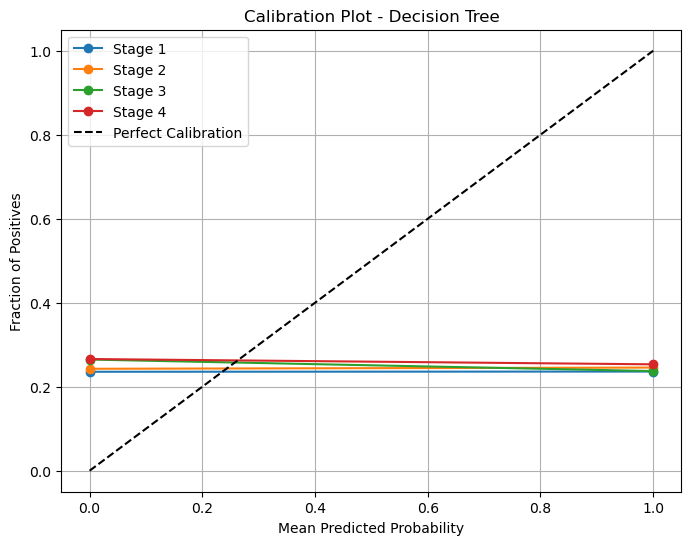

In [37]:
# getting predicted probabilities from decision tree
dt_probs = dt_model.predict_proba(X_test)

# getting the class labels
classes = dt_model.classes_

# binarising y_test for one-vs-rest calibration plotting
y_test_bin = label_binarize(y_test, classes=classes)

# plotting calibration curve
plt.figure(figsize=(8, 6))

# loop through each fibrosis stage
for i, class_label in enumerate(classes):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin[:, i],
        dt_probs[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=f'Stage {class_label}')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Decision Tree')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

Calibration plot - Random Forest

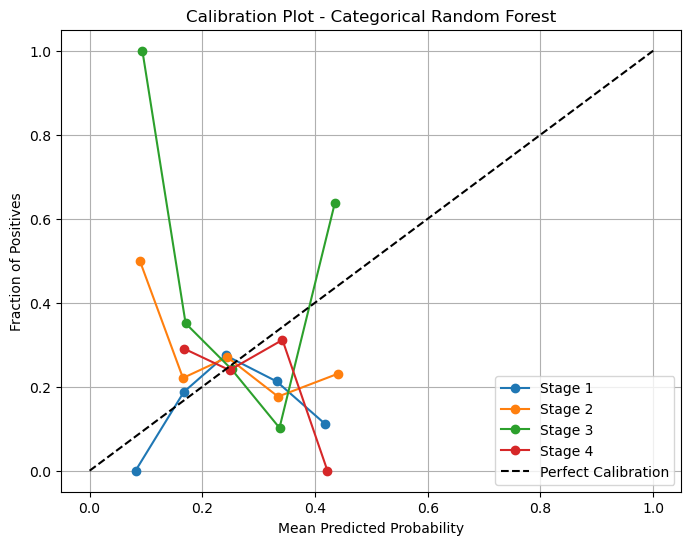

In [38]:
# getting predicted probabilities from categorical random forest
rf_cat_probs = rf_model.predict_proba(X_test)

# getting the class labels
classes = rf_model.classes_

# binarising y_test for one-vs-rest calibration plotting
y_test_bin = label_binarize(y_test, classes=classes)

# plotting calibration curve
plt.figure(figsize=(8, 6))

# loop through each fibrosis stage
for i, class_label in enumerate(classes):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin[:, i],
        rf_cat_probs[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=f'Stage {class_label}')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Categorical Random Forest')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# **t-SNE**

Data transformation

In [39]:
# transforming features before t-SNE
qt = QuantileTransformer(output_distribution='normal', random_state=42)

X_tsne_ready = qt.fit_transform(X)

# checking transformed shape
print(X_tsne_ready.shape)

(1313, 21)


t-SNE model

In [40]:
# defining t-SNE model
tsne_model = TSNE(
    n_components=2,      # reduce into 2 dimensions
    perplexity=30,       # common starting point
    learning_rate='auto',
    init='pca',
    random_state=42
)

# fitting and transforming the data
X_tsne = tsne_model.fit_transform(X_tsne_ready)

# putting t-SNE result into a dataframe
tsne_df = pd.DataFrame(X_tsne, columns=['tSNE_1', 'tSNE_2'])

# adding fibrosis stage labels
tsne_df['Baselinehistological staging'] = y.values

# checking first few rows
tsne_df.head()

,tSNE_1,tSNE_2,Baselinehistological staging
0,5.143677,-33.035847,2
1,10.862486,2.614206,3
2,-28.038698,-0.682580,4
3,-3.953360,-39.253204,4
4,2.180464,-4.753232,3


t-SNA plot

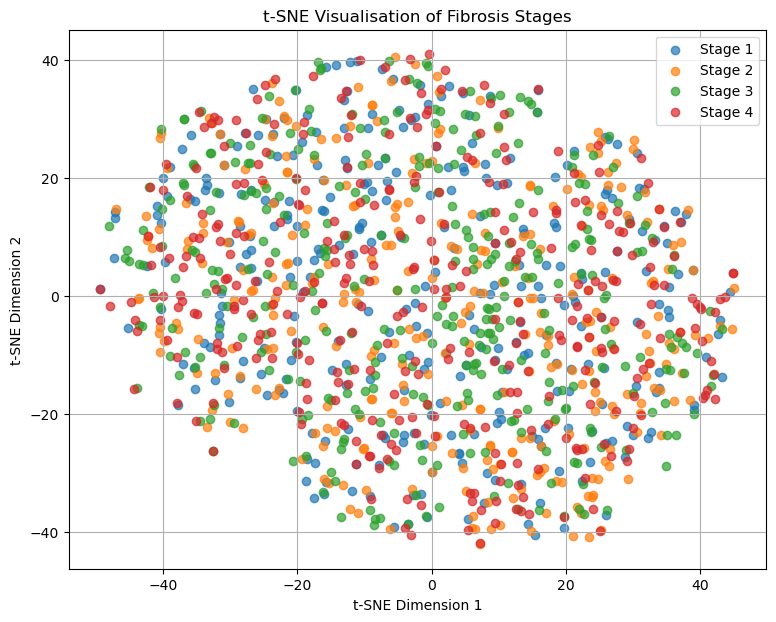

In [41]:
# plotting t-SNE visualisation
plt.figure(figsize=(9, 7))

# loop through each fibrosis stage
for stage in sorted(tsne_df['Baselinehistological staging'].unique()):

    # filtering points for each stage
    subset = tsne_df[tsne_df['Baselinehistological staging'] == stage]

    # plotting the points
    plt.scatter(
        subset['tSNE_1'],
        subset['tSNE_2'],
        label=f'Stage {stage}',
        alpha=0.7
    )

# formatting plot
plt.title('t-SNE Visualisation of Fibrosis Stages')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend()
plt.grid(True)
plt.show()

The t-SNE plot shows heavy overlap between all four fibrosis stages, suggesting that the available clinical features do not naturally separate patients into distinct stage-specific clusters.